# Лабораторная работа: Регрессия — ансамблевые методы (assembling / metode mixte)

**Цель:** на датасете цен на недвижимость построить и сравнить три регрессионные модели:
`RandomForestRegressor` (бэггинг деревьев) и `GradientBoostingRegressor` (бустинг) и `StackingRegressor` (стекинг моделей).

**Файл данных:** `real_estate_regression_dataset.csv`.


## Глава 1. Загрузка и первичный анализ данных
Подключаем библиотеки, загружаем файл и смотрим, что в нём есть: размер, типы признаков, пропуски и дубликаты.


In [1]:
# Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge

sns.set_theme(style="whitegrid")   # единый стиль графиков
pd.set_option("display.max_columns", 50)

In [2]:
# Загрузка данных
df = pd.read_csv("../data/real_estate_regression_dataset.csv")
print("Строк:", df.shape[0], "| Столбцов:", df.shape[1])
df.head()

Строк: 2840 | Столбцов: 28


,Id,Neighborhood,PropertyType,OverallQual,Condition,RenovationQuality,GrLivArea,LotArea,TotalBsmtSF,Rooms,Bedrooms,Bathrooms,Floor,TotalFloors,YearBuilt,YearRenovated,PropertyAge,GarageType,GarageCars,GarageArea,HeatingType,EnergyEfficiency,DistanceToCenter,HasPool,HasBalcony,CrimeRate,SchoolRating,SalePrice
0,994,GreenPark,Townhouse,9,Average,High,121,154.0,104.0,5,4,2,1,2,2016,2024.0,8,Detached,1,22.0,Electric,98.0,4.8,0,0,4.8,9.1,641900
1,279,Eastgate,House,9,Fair,Medium,90,1227.0,50.0,4,3,3,1,2,1982,2018.0,42,Attached,1,17.0,Gas,97.0,7.7,0,0,3.5,5.4,283500
2,820,OldTown,Apartment,4,Good,Low,104,0.0,0.0,3,2,1,1,5,1992,2024.0,32,NoGarage,0,0.0,Gas,97.0,2.5,0,0,4.6,5.9,365300
3,2700,Eastgate,Apartment,5,Good,Low,80,0.0,0.0,4,1,2,6,10,2012,2024.0,12,Underground,1,30.0,District,100.0,8.4,0,1,5.2,9.5,341200
4,1205,Downtown,House,9,Excellent,Medium,156,583.0,135.0,7,5,3,1,1,2018,2024.0,6,Detached,2,49.0,Electric,100.0,0.3,1,0,7.0,6.7,1238000


In [3]:
# Названия признаков и их типы
df.dtypes

Id                     int64
Neighborhood          object
PropertyType          object
OverallQual            int64
Condition             object
RenovationQuality     object
GrLivArea              int64
LotArea              float64
TotalBsmtSF          float64
Rooms                  int64
Bedrooms               int64
Bathrooms              int64
Floor                  int64
TotalFloors            int64
YearBuilt              int64
YearRenovated        float64
PropertyAge            int64
GarageType            object
GarageCars             int64
GarageArea           float64
HeatingType           object
EnergyEfficiency     float64
DistanceToCenter     float64
HasPool                int64
HasBalcony             int64
CrimeRate            float64
SchoolRating         float64
SalePrice              int64
dtype: object

In [4]:
# Пропущенные значения (только столбцы, где они есть) и полные дубликаты
missing = df.isna().sum()
print("Пропуски по столбцам:")
print(missing[missing > 0].sort_values(ascending=False))
print("\nПолных дубликатов:", df.duplicated().sum())

Пропуски по столбцам:
EnergyEfficiency     310
YearRenovated        251
TotalBsmtSF          249
RenovationQuality    245
GarageType           182
SchoolRating         179
HeatingType          162
CrimeRate            150
Condition            145
LotArea              145
GarageArea           122
dtype: int64

Полных дубликатов: 40


## Глава 2. Очистка и подготовка данных
1. Удаляем полные дубликаты (одинаковые строки не несут новой информации и искажают оценку качества).
2. **Выбросы не удаляем:** очень большие дома и дорогие объекты возможны в реальности, и модели должны уметь с ними работать.
3. Пропуски заполним **внутри Pipeline** (глава 4).

> **Что такое утечка данных и зачем Pipeline?** Если заполнить пропуски медианой по *всей* таблице до разделения на train/test, то медиана «подсмотрит» значения тестовых объектов — оценка станет слишком оптимистичной. `Pipeline` + `ColumnTransformer` считают медианы и категории **только по обучающей выборке**, а затем применяют их к тестовой.

In [5]:
# Удаляем полные дубликаты
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Удалено дубликатов: {before - len(df)}. Осталось строк: {len(df)}")

# Сохраняем очищенный от дубликатов набор (пропуски пока оставляем)
df.to_csv("real_estate_cleaned.csv", index=False)

Удалено дубликатов: 40. Осталось строк: 2800


## Глава 3. Краткий анализ данных
Смотрим основные статистики и два-три графика, важных для регрессии.

In [6]:
# Основные статистические характеристики числовых признаков
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Id,2800.0,1400.5,808.4,1.0,700.8,1400.5,2100.2,2800.0
OverallQual,2800.0,6.1,1.6,1.0,5.0,6.0,7.0,10.0
GrLivArea,2800.0,129.1,58.9,29.0,85.0,120.0,159.0,538.0
LotArea,2659.0,339.9,558.4,0.0,0.0,224.0,466.0,11197.0
TotalBsmtSF,2554.0,55.6,56.5,0.0,0.0,54.0,92.0,449.0
Rooms,2800.0,5.4,1.8,2.0,4.0,5.0,6.0,11.0
Bedrooms,2800.0,3.4,1.6,1.0,2.0,3.0,4.0,12.0
Bathrooms,2800.0,2.2,1.0,1.0,1.0,2.0,3.0,7.0
Floor,2800.0,2.6,3.3,1.0,1.0,1.0,2.0,19.0
TotalFloors,2800.0,4.7,5.1,1.0,2.0,2.0,6.0,19.0


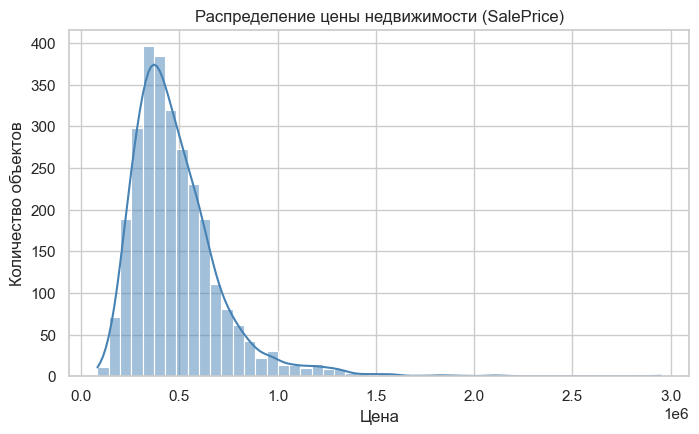

In [7]:
# Гистограмма распределения цены
plt.figure(figsize=(8, 4.5))
sns.histplot(df["SalePrice"], bins=50, kde=True, color="steelblue")
plt.title("Распределение цены недвижимости (SalePrice)")
plt.xlabel("Цена")
plt.ylabel("Количество объектов")
plt.show()

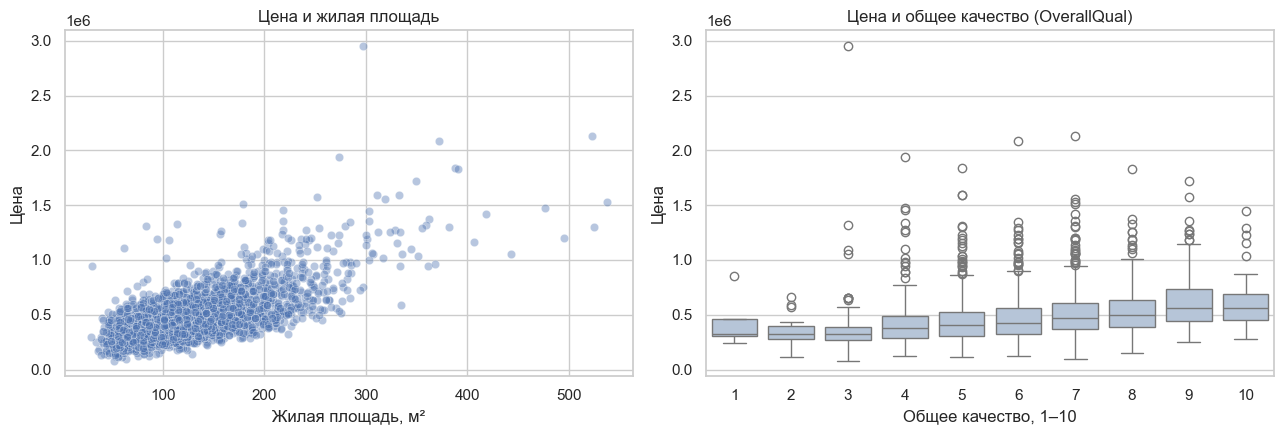

In [8]:
# Зависимость цены от жилой площади и от качества
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.4, ax=axes[0])
axes[0].set_title("Цена и жилая площадь")
axes[0].set_xlabel("Жилая площадь, м²")
axes[0].set_ylabel("Цена")

sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=axes[1], color="lightsteelblue")
axes[1].set_title("Цена и общее качество (OverallQual)")
axes[1].set_xlabel("Общее качество, 1–10")
axes[1].set_ylabel("Цена")

plt.tight_layout()
plt.show()

## Глава 4. Подготовка к регрессии
- `y` — целевой признак `SalePrice`;
- `X` — все остальные признаки, **кроме `Id`** (это просто номер строки, он не влияет на цену);
- разделение 80% / 20% с фиксированным `random_state=42`, чтобы результаты повторялись;
- `ColumnTransformer` обрабатывает числа (медиана + масштабирование) и категории (самое частое значение + One-Hot кодирование) отдельно.

In [9]:
# Целевой признак и признаки
y = df["SalePrice"]
X = df.drop(columns=["SalePrice", "Id"])

# Разделение на обучающую и тестовую выборки (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Обучающая выборка:", X_train.shape, "| Тестовая:", X_test.shape)

Обучающая выборка: (2240, 26) | Тестовая: (560, 26)


In [10]:
# Списки числовых и категориальных признаков
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Числовые:", len(num_cols), "| Категориальные:", cat_cols)

# Числа: пропуски -> медиана, затем масштабирование
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
# Категории: пропуски -> самое частое значение, затем One-Hot
# handle_unknown="ignore" нужен, чтобы редкие категории из теста не вызывали ошибку
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

Числовые: 20 | Категориальные: ['Neighborhood', 'PropertyType', 'Condition', 'RenovationQuality', 'GarageType', 'HeatingType']


## Глава 5. Построение регрессионных моделей
Каждая модель — это `Pipeline` из предобработки и самой модели. Обучаем все три **только на обучающей выборке**.

- **RandomForestRegressor** — много деревьев на случайных подвыборках, ответ — среднее (бэггинг).
- **GradientBoostingRegressor** — деревья строятся последовательно, каждое исправляет ошибки предыдущих (бустинг).
- **StackingRegressor** — метод объединения нескольких моделей, в котором Random Forest и Gradient Boosting формируют базовые прогнозы, а дополнительная модель Ridge обучается комбинировать их для получения итогового предсказания (стекинг).

In [11]:
# Три модели, каждая в своём Pipeline
models = {
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),

    # параметры бустинга подобраны кросс-валидацией на обучающей выборке (тест не использовался)
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=500, learning_rate=0.05,
                                                   max_depth=3, subsample=0.8, random_state=42),

    "Stacking Regressor": StackingRegressor(
        estimators=[
            ("rf", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
            ("gb", GradientBoostingRegressor(n_estimators=500, learning_rate=0.05,
                                             max_depth=3, subsample=0.8, random_state=42))
        ],
        final_estimator=Ridge(),
        cv=5,
        n_jobs=-1
    ),
}

pipelines = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)        # обучение только на train
    pipelines[name] = pipe
    print("Обучена модель:", name)


Обучена модель: Random Forest
Обучена модель: Gradient Boosting
Обучена модель: Stacking Regressor


## Глава 6. Оценка качества моделей
Считаем на **одной и той же тестовой выборке**:
- **MAE** — средняя абсолютная ошибка (в тех же единицах, что и цена);
- **RMSE** — корень из среднего квадрата ошибки; сильнее штрафует крупные промахи;
- **R²** — доля разброса цен, объяснённая моделью (1 — идеально, 0 — не лучше среднего).

In [12]:
# Предсказания и метрики
preds = {}
rows = []
for name, pipe in pipelines.items():
    p = pipe.predict(X_test)
    preds[name] = p
    rows.append({
        "Модель": name,
        "MAE": mean_absolute_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R2": r2_score(y_test, p),
    })

results = pd.DataFrame(rows).set_index("Модель").round(3)
results.sort_values("RMSE")

,MAE,RMSE,R2
Модель,,,
Stacking Regressor,48912.058,75026.354,0.891
Gradient Boosting,48911.073,75065.006,0.891
Random Forest,63987.140,93455.498,0.831


In [13]:
# Лучшая модель по каждой метрике
best_mae = results["MAE"].idxmin()
best_rmse = results["RMSE"].idxmin()
best_r2 = results["R2"].idxmax()
print("Лучшая по MAE: ", best_mae)
print("Лучшая по RMSE:", best_rmse)
print("Лучшая по R²:  ", best_r2)

Лучшая по MAE:  Gradient Boosting
Лучшая по RMSE: Stacking Regressor
Лучшая по R²:   Gradient Boosting


## Глава 7. Графики регрессии
Три графика: фактические и предсказанные значения, диаграммы рассеяния с линией идеального предсказания и сравнение ошибок моделей.

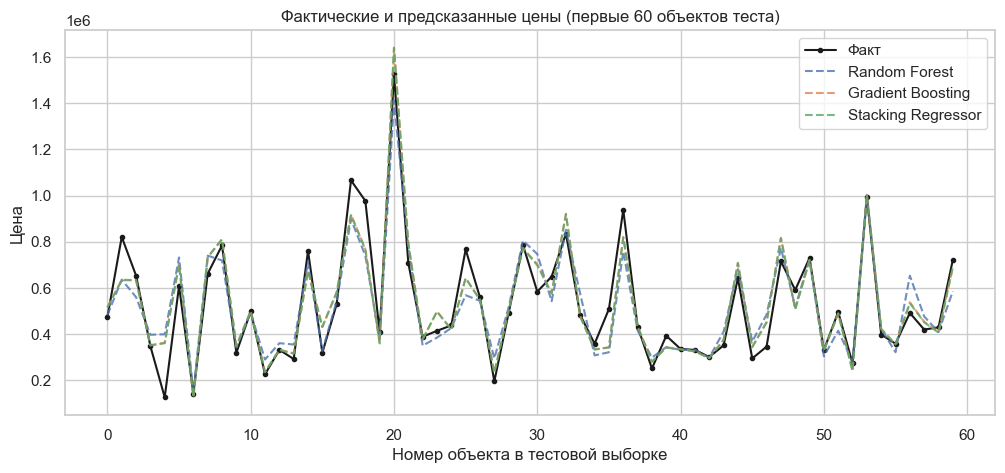

In [14]:
# График 1: факт и прогноз для первых 60 объектов тестовой выборки
n = 60
plt.figure(figsize=(12, 5))
plt.plot(range(n), y_test.values[:n], "k-o", markersize=3, label="Факт")
for name, p in preds.items():
    plt.plot(range(n), p[:n], "--", alpha=0.8, label=name)
plt.title("Фактические и предсказанные цены (первые 60 объектов теста)")
plt.xlabel("Номер объекта в тестовой выборке")
plt.ylabel("Цена")
plt.legend()
plt.show()

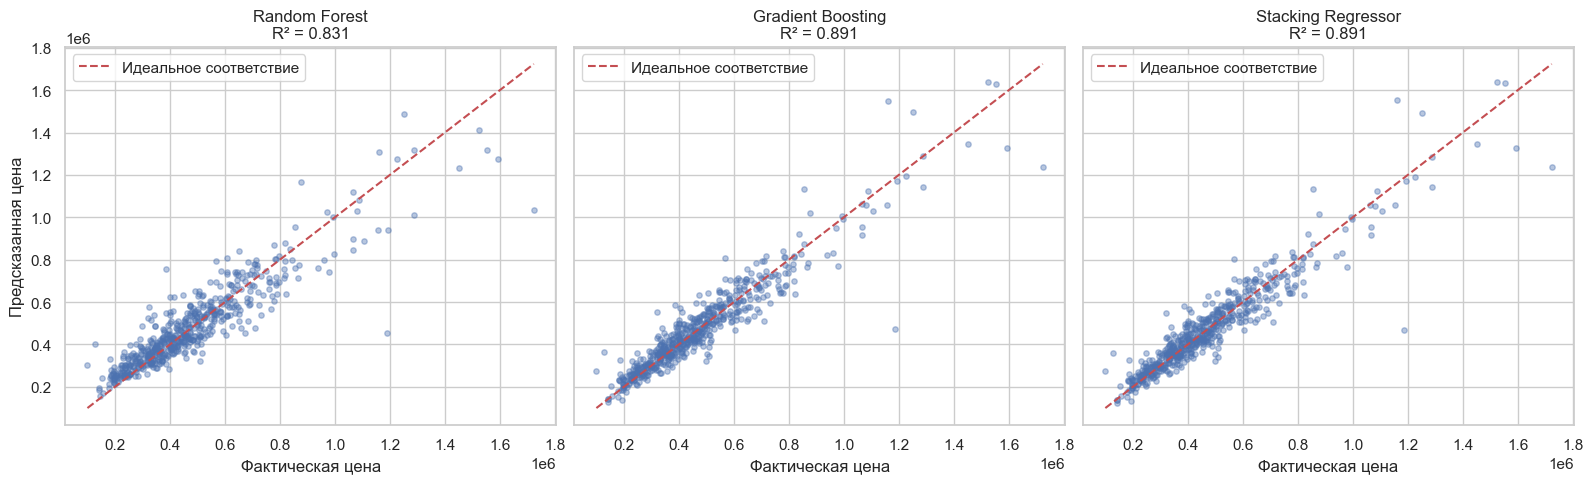

In [15]:
# График 2: диаграммы рассеяния «факт — прогноз» с линией идеального соответствия
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lim = [min(y_test.min(), min(p.min() for p in preds.values())),
       max(y_test.max(), max(p.max() for p in preds.values()))]
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.4, s=15)
    ax.plot(lim, lim, "r--", label="Идеальное соответствие")
    ax.set_title(f"{name}\nR² = {r2_score(y_test, p):.3f}")
    ax.set_xlabel("Фактическая цена")
    ax.legend()
axes[0].set_ylabel("Предсказанная цена")
plt.tight_layout()
plt.show()

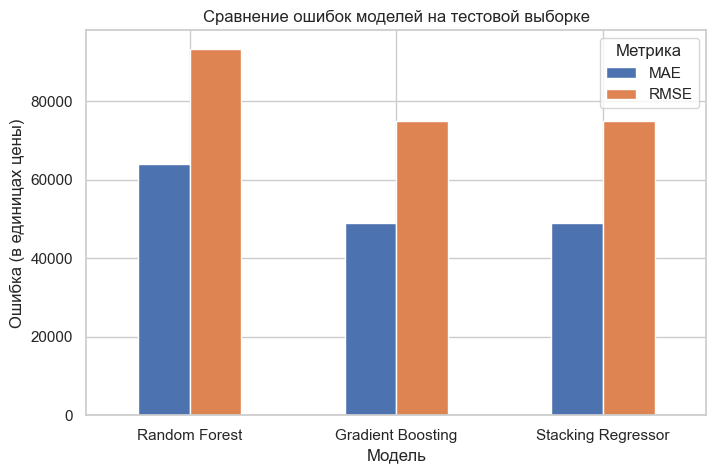

In [16]:
# График 3: сравнение MAE и RMSE
results[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 5), rot=0)
plt.title("Сравнение ошибок моделей на тестовой выборке")
plt.xlabel("Модель")
plt.ylabel("Ошибка (в единицах цены)")
plt.legend(title="Метрика")
plt.show()

## Глава 8. Заключение
Текст ниже формируется автоматически по реальным результатам, полученным выше.

In [17]:
# Автоматический вывод по таблице метрик
best = results["RMSE"].idxmin()
worst = results["RMSE"].idxmax()
mean_price = y_test.mean()
b = results.loc[best]

print(f"Выполнено: загрузка и очистка данных (удалены дубликаты), краткий анализ, "
      f"разделение 80/20 и обучение трёх моделей через Pipeline.")
print(f"Всего объектов после очистки: {len(df)}; тестовая выборка: {len(X_test)}.")
print()
print(f"Лучший результат по RMSE показала модель «{best}»: "
      f"MAE = {b['MAE']:,.0f}, RMSE = {b['RMSE']:,.0f}, R² = {b['R2']:.3f}.")
print(f"По MAE лучшей оказалась модель «{results['MAE'].idxmin()}» (MAE = {results['MAE'].min():,.0f}).")
print(f"Худший результат у модели «{worst}» (RMSE = {results.loc[worst, 'RMSE']:,.0f}).")
print(f"Средняя ошибка MAE лучшей модели — около {b['MAE'] / mean_price * 100:.1f}% "
      f"от средней цены в тесте ({mean_price:,.0f}).")
print(f"R² = {b['R2']:.3f} — коэффициент детерминации лучшей модели по RMSE.")

Выполнено: загрузка и очистка данных (удалены дубликаты), краткий анализ, разделение 80/20 и обучение трёх моделей через Pipeline.
Всего объектов после очистки: 2800; тестовая выборка: 560.

Лучший результат по RMSE показала модель «Stacking Regressor»: MAE = 48,912, RMSE = 75,026, R² = 0.891.
По MAE лучшей оказалась модель «Gradient Boosting» (MAE = 48,911).
Худший результат у модели «Random Forest» (RMSE = 93,455).
Средняя ошибка MAE лучшей модели — около 10.3% от средней цены в тесте (476,718).
R² = 0.891 — коэффициент детерминации лучшей модели по RMSE.


- Если одна из ансамблевых моделей оказалась не лучше остальных, это может быть связано с особенностями синтетических данных: цена в основном зависит от площади, качества и района. Более сложная модель не обязательно даёт лучший результат.
- RMSE обычно больше MAE, поскольку сильнее учитывает крупные ошибки и чувствительнее к выбросам.
- Модели можно улучшить подбором гиперпараметров (GridSearchCV) или изменением состава ансамбля, например, с помощью VotingRegressor и StackingRegressor.